# P05: data cleaning + RAG (Person 2)

AI-assisted code (mark this in the final notebook). Builds on Person 1's `data.py` and `config.py`, and on sir's RAG_Pipeline_Lab (embeddings, FAISS, BM25, RRF).

**Run in order.** Part A cleans the data and saves ID files. Part B builds the RAG index and compares retrieval settings on the validation set.

Share these files with the group when done: `clean_train_ids.json`, `clean_val_ids.json`, `clean_test_ids.json`, `excluded_ids.json`, `filter_report.json`.

## Part A: clean the data

### A1. Setup

In [25]:
import json, re, random, time
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from data import load_data, run_sql, same_result
from config import CONFIG, SEED, QUICK_RUN, set_seed
set_seed()

TEST_SIZE = 300
VAL_SIZE = 300
QUICK_TEST = 20      
AUDIT_N = 60        
CACHE = Path("clean_data"); CACHE.mkdir(exist_ok=True)   

### A2. Load the raw data

In [26]:
ds = load_data()
import warnings
warnings.filterwarnings("ignore")
raw_train, raw_test = ds["train"], ds["test"]
print(len(raw_train), len(raw_test))

100000 5851


In [27]:
ex=raw_train[0]
ex

{'id': 5097,
 'domain': 'forestry',
 'domain_description': 'Comprehensive data on sustainable forest management, timber production, wildlife habitat, and carbon sequestration in forestry.',
 'sql_complexity': 'single join',
 'sql_complexity_description': 'only one join (specify inner, outer, cross)',
 'sql_task_type': 'analytics and reporting',
 'sql_task_type_description': 'generating reports, dashboards, and analytical insights',
 'sql_prompt': 'What is the total volume of timber sold by each salesperson, sorted by salesperson?',
 'sql_context': "CREATE TABLE salesperson (salesperson_id INT, name TEXT, region TEXT); INSERT INTO salesperson (salesperson_id, name, region) VALUES (1, 'John Doe', 'North'), (2, 'Jane Smith', 'South'); CREATE TABLE timber_sales (sales_id INT, salesperson_id INT, volume REAL, sale_date DATE); INSERT INTO timber_sales (sales_id, salesperson_id, volume, sale_date) VALUES (1, 1, 120, '2021-01-01'), (2, 1, 150, '2021-02-01'), (3, 2, 180, '2021-01-01');",
 'sql'

### A3. Check every gold query
A gold query is kept only if it is a SELECT, runs without error, and gives a non-trivial result.

In [28]:
def check_example(ex):
    """Return a reason string: 'ok' or why the example must be removed."""
    sql = ex["sql"].strip()
    if not sql.lower().startswith(("select", "with")):
        return "not_select"
    rows, err = run_sql(ex["sql_context"], sql)
    if err is not None:
        e = err.lower()
        if "no such table" in e:    return "missing_table"
        if "no such column" in e:   return "missing_column"
        if "no such function" in e: return "unsupported_function"
        if "syntax error" in e:     return "syntax_dialect"
        if "timed out" in e:        return "timeout"
        if "setup error" in e:      return "bad_context"
        return "other_error"
    if not rows:
        return "empty_result"
    if len(rows) == 1 and len(rows[0]) == 1 and rows[0][0] in (0, None, ""):
        return "trivial_result"
    return "ok"



In [29]:
CHECK_CACHE_VERSION = 2

def run_checks(split, name):
    cache = CACHE / f"checks_{name}_v{CHECK_CACHE_VERSION}.json"

    metadata = {
        "version": CHECK_CACHE_VERSION,
        "split": name,
        "n": len(split),
        "first_id": split[0]["id"] if len(split) else None,
        "last_id": split[-1]["id"] if len(split) else None,
    }

    if cache.exists():
        try:
            with cache.open("r", encoding="utf-8") as f:
                saved = json.load(f)

            if (
                saved.get("metadata") == metadata
                and isinstance(saved.get("checks"), dict)
            ):
                return saved["checks"]
        except (OSError, json.JSONDecodeError, AttributeError):
            pass

    res = {}
    for ex in tqdm(split, desc=name):
        res[str(ex["id"])] = check_example(ex)

    with cache.open("w", encoding="utf-8") as f:
        json.dump(
            {"metadata": metadata, "checks": res},
            f,
            indent=2,
        )

    return res

test_checks = run_checks(raw_test, "test")      
train_checks = run_checks(raw_train, "train")   

def report(res, name):
    c = Counter(res.values())
    df = pd.DataFrame({"count": c}).sort_values("count", ascending=False)
    df["pct"] = (df["count"] / len(res) * 100).round(1)
    print(f"\n{name}: {len(res)} checked")
    display(df)

report(test_checks, "official test")
report(train_checks, "official train")

test:   0%|          | 0/5851 [00:00<?, ?it/s]

train:   0%|          | 0/100000 [00:00<?, ?it/s]


official test: 5851 checked


,count,pct
ok,3079,52.6
not_select,613,10.5
empty_result,592,10.1
syntax_dialect,428,7.3
trivial_result,348,5.9
missing_column,288,4.9
unsupported_function,205,3.5
missing_table,170,2.9
other_error,78,1.3
bad_context,50,0.9



official train: 100000 checked


,count,pct
ok,52182,52.2
not_select,10243,10.2
empty_result,9621,9.6
syntax_dialect,7713,7.7
trivial_result,6033,6.0
missing_column,4783,4.8
unsupported_function,3942,3.9
missing_table,3284,3.3
other_error,1498,1.5
bad_context,701,0.7


### A4. Remove duplicates and leakage, then split
Clean first, then split into train, validation and test. The test set is spread evenly across `sql_complexity` levels.

In [30]:
norm = lambda s: re.sub(r"\s+", " ", s.lower().strip())

train_idx = {i: k for k, i in enumerate(raw_train["id"])}
test_idx = {i: k for k, i in enumerate(raw_test["id"])}
train_prompt = dict(zip(raw_train["id"], map(norm, raw_train["sql_prompt"])))
test_prompt = dict(zip(raw_test["id"], map(norm, raw_test["sql_prompt"])))
train_cx = dict(zip(raw_train["id"], raw_train["sql_complexity"]))
test_cx = dict(zip(raw_test["id"], raw_test["sql_complexity"]))
all_test_prompts = set(test_prompt.values())

# equal share per complexity level (moved up so val can use it too)
def stratified_sample(ids, groups, n, seed=SEED):
    rng = random.Random(seed)
    by = {}
    for i, g in zip(ids, groups):
        by.setdefault(g, []).append(i)
    for v in by.values():
        rng.shuffle(v)
    out = []
    while len(out) < n and any(by.values()):
        for g in sorted(by):
            if by[g] and len(out) < n:
                out.append(by[g].pop())
    rng.shuffle(out)
    return out

# train: keep clean examples, drop duplicates and anything whose question appears in test
seen, clean_train, dropped = set(), [], Counter()
for sid, reason in train_checks.items():
    if reason != "ok":
        continue
    i = int(sid); p = train_prompt[i]
    if p in all_test_prompts:
        dropped["question_in_test"] += 1; continue
    if p in seen:
        dropped["duplicate_question"] += 1; continue
    seen.add(p); clean_train.append(i)
print("clean train after dedupe:", len(clean_train), dict(dropped))

# validation: carved out of the clean train pool, stratified like test
val_ids = stratified_sample(clean_train, [train_cx[i] for i in clean_train], VAL_SIZE)
val_set = set(val_ids)
train_ids = [i for i in clean_train if i not in val_set]

# test candidates: clean examples, equal share per complexity level
clean_test = [int(s) for s, r in test_checks.items() if r == "ok"]
print("clean test pool:", len(clean_test))
cand = stratified_sample(clean_test, [test_cx[i] for i in clean_test], TEST_SIZE + 40)
print("test candidates:", len(cand), "| train:", len(train_ids), "| val:", len(val_ids))

print(pd.Series([train_cx[i] for i in val_ids]).value_counts())    # check: roughly equal per level

clean train after dedupe: 52158 {'duplicate_question': 21, 'question_in_test': 3}
clean test pool: 3079
test candidates: 340 | train: 51858 | val: 300
set operations      43
basic SQL           43
single join         43
aggregation         43
multiple_joins      43
subqueries          43
window functions    42
Name: count, dtype: int64


In [ ]:
test_ids = [i for i in cand ][:TEST_SIZE]
train_ids = [i for i in train_ids]
val_ids = [i for i in val_ids ]

### A5. Overlap checks and save

In [ ]:
train_p = {train_prompt[i] for i in train_ids}
val_p = {train_prompt[i] for i in val_ids}
test_p = {test_prompt[i] for i in test_ids}
assert not (train_p & val_p) and not (train_p & test_p) and not (val_p & test_p), "question overlap!"
print("question overlap between train/val/test: 0")

def pick(split, index, ids):
    return split.select([index[i] for i in ids])

train_pool = pick(raw_train, train_idx, train_ids)
val_ds = pick(raw_train, train_idx, val_ids)
test_ds = pick(raw_test, test_idx, test_ids)

shared_ctx = set(train_pool["sql_context"]) & set(test_ds["sql_context"])
print("test examples whose exact schema also appears in train:",
      sum(c in shared_ctx for c in test_ds["sql_context"]), "of", len(test_ds))

print(pd.Series(test_ds["sql_complexity"]).value_counts())

json.dump(train_ids, open("clean_train_ids.json", "w"))
json.dump(val_ids, open("clean_val_ids.json", "w"))
json.dump(test_ids, open("clean_test_ids.json", "w"))

json.dump({
    "test_checks": dict(Counter(test_checks.values())),
    "train_checks": dict(Counter(train_checks.values())),
    "train_dropped_after_checks": dict(dropped),
    "final_sizes": {"train": len(train_ids), "val": len(val_ids), "test": len(test_ids)},
}, open("filter_report_rag.json", "w"), indent=2)
print("saved ID files and filter_report_rag.json")

question overlap between train/val/test: 0
test examples whose exact schema also appears in train: 31 of 300
aggregation         52
basic SQL           50
single join         47
subqueries          44
window functions    43
multiple_joins      43
set operations      21
Name: count, dtype: int64
saved ID files and filter_report_rag.json



## A6. Exploratory Data Analysis and Cleaning Summary

This section summarizes automated cleaning results, the final dataset splits, SQL complexity, domain distribution, and prompt/SQL lengths.


In [35]:
print("=== Cleaning Summary ===")

for name, checks in [("Official train", train_checks), ("Official test", test_checks)]:
    counts = Counter(checks.values())
    print(f"\n{name}: {len(checks):,} examples checked")
    print(f"Kept by automated checks: {counts.get('ok', 0):,}")
    print(f"Removed by automated checks: {len(checks) - counts.get('ok', 0):,}")

print("\n=== Final Split Sizes ===")
print(f"Train      : {len(train_pool):,}")
print(f"Validation : {len(val_ds):,}")
print(f"Test       : {len(test_ds):,}")
print(f"Train duplicates / test-question overlap removed: {sum(dropped.values()):,}")
print(f"Manually flagged test examples: {len(FLAGGED_TEST)}")

=== Cleaning Summary ===

Official train: 100,000 examples checked
Kept by automated checks: 52,182
Removed by automated checks: 47,818

Official test: 5,851 examples checked
Kept by automated checks: 3,079
Removed by automated checks: 2,772

=== Final Split Sizes ===
Train      : 51,858
Validation : 300
Test       : 300
Train duplicates / test-question overlap removed: 24
Manually flagged test examples: 2


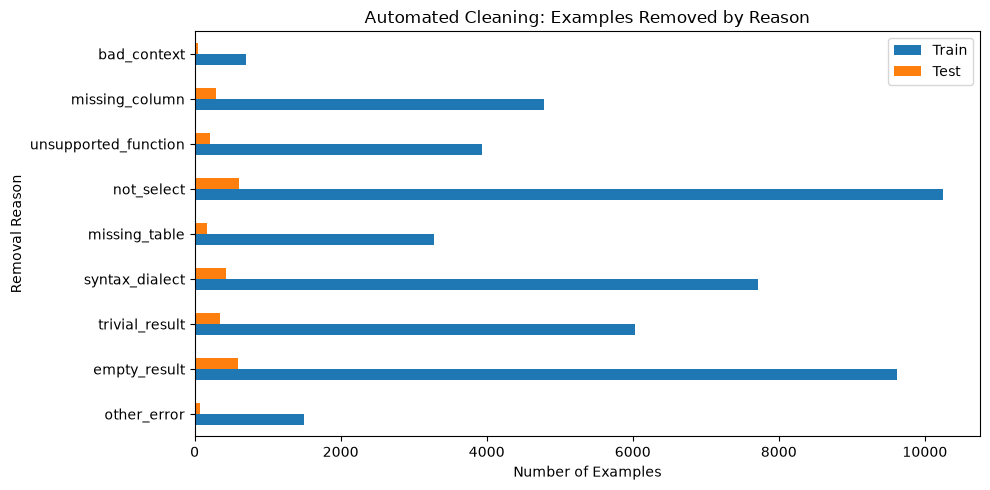

In [36]:
removal_counts = pd.DataFrame({
    "Train": Counter(r for r in train_checks.values() if r != "ok"),
    "Test": Counter(r for r in test_checks.values() if r != "ok"),
}).fillna(0).astype(int)

removal_counts.plot(kind="barh", figsize=(10, 5))
plt.xlabel("Number of Examples")
plt.ylabel("Removal Reason")
plt.title("Automated Cleaning: Examples Removed by Reason")
plt.tight_layout()
plt.show()

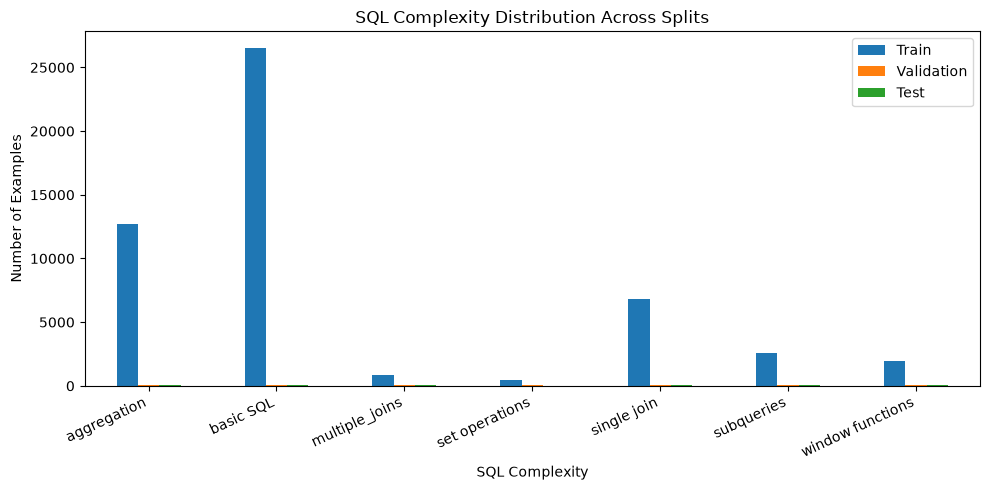

In [37]:
complexities = sorted(set(train_pool["sql_complexity"]) |
                      set(val_ds["sql_complexity"]) |
                      set(test_ds["sql_complexity"]))

complexity_counts = pd.DataFrame({
    "Train": Counter(train_pool["sql_complexity"]),
    "Validation": Counter(val_ds["sql_complexity"]),
    "Test": Counter(test_ds["sql_complexity"]),
}).reindex(complexities, fill_value=0)

complexity_counts.plot(kind="bar", figsize=(10, 5))
plt.xlabel("SQL Complexity")
plt.ylabel("Number of Examples")
plt.title("SQL Complexity Distribution Across Splits")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

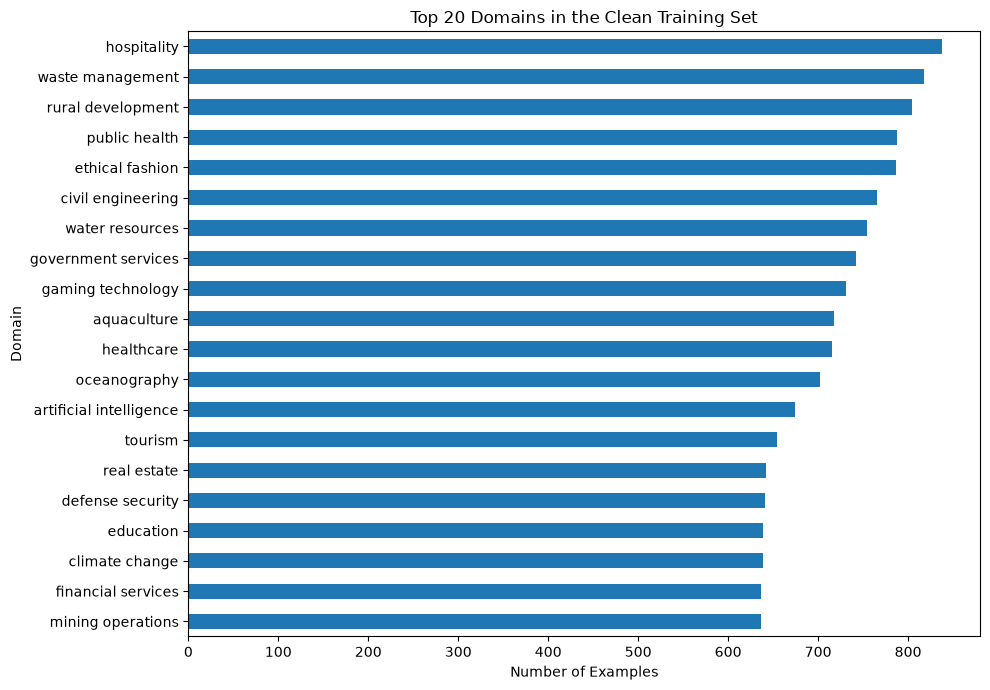

Total unique domains: 100


In [38]:
domain_counts = Counter(train_pool["domain"])
top20 = pd.Series(dict(domain_counts.most_common(20))).sort_values()

top20.plot(kind="barh", figsize=(10, 7))
plt.xlabel("Number of Examples")
plt.ylabel("Domain")
plt.title("Top 20 Domains in the Clean Training Set")
plt.tight_layout()
plt.show()

print(f"Total unique domains: {len(domain_counts)}")

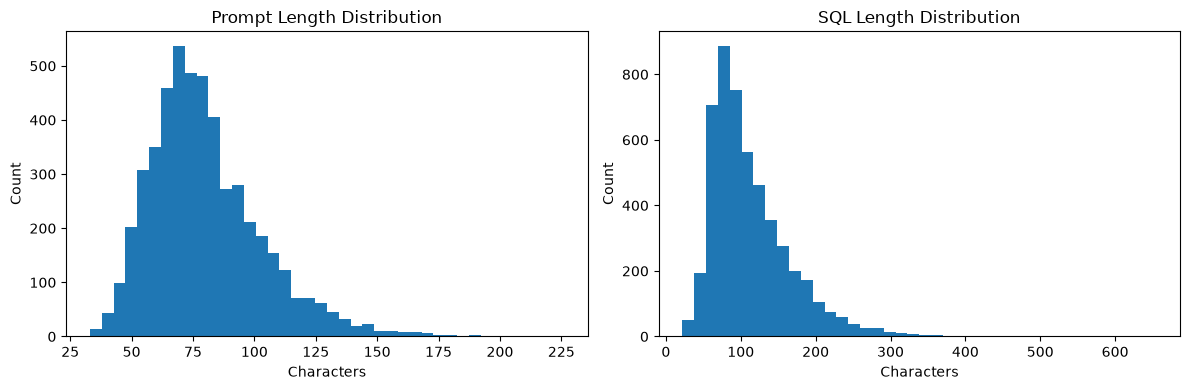

Sample size: 5,000
Mean prompt length: 80.2 characters
Mean SQL length: 113.2 characters


In [39]:
sample_size = min(5000, len(train_pool))
sample_indices = random.Random(SEED).sample(range(len(train_pool)), sample_size)
sample = train_pool.select(sample_indices)

prompt_lens = [len(x) for x in sample["sql_prompt"]]
sql_lens = [len(x) for x in sample["sql"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(prompt_lens, bins=40)
axes[0].set_title("Prompt Length Distribution")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Count")

axes[1].hist(sql_lens, bins=40)
axes[1].set_title("SQL Length Distribution")
axes[1].set_xlabel("Characters")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Sample size: {sample_size:,}")
print(f"Mean prompt length: {np.mean(prompt_lens):.1f} characters")
print(f"Mean SQL length: {np.mean(sql_lens):.1f} characters")

## Part B: RAG

### B1. Settings

In [40]:
SCHEMA_MODE = "full"          # "full" = whole sql_context, "create" = CREATE statements only

K = 3
RETRIEVAL = "masked"           # dense | bm25 | hybrid | masked
INDEX_N = None
print(f"Quick Run: {QUICK_RUN} | INDEX_N: {INDEX_N}")

Quick Run: False | INDEX_N: None


### B2. Schema helpers and question masking (your own idea)
Masking replaces table names, column names, quoted values and numbers in the question with placeholders, so retrieval matches the *shape* of the question and not its topic words.

In [11]:
import re

def schema_text(ctx, mode=None):
    mode = mode or SCHEMA_MODE
    if mode == "create":
        stmts = re.findall(r"CREATE\s+TABLE[^;]*;", ctx, flags=re.I | re.S)
        return "\n".join(stmts) if stmts else ctx
    return ctx

def schema_names(ctx):
    """Table and column names from the CREATE TABLE statements."""
    tables, cols = set(), set()
    pat = r"CREATE\s+TABLE\s+(?:IF NOT EXISTS\s+)?[`\"\[]?(\w+)[`\"\]]?\s*\((.*?)\)\s*;"
    for m in re.finditer(pat, ctx, flags=re.I | re.S):
        tables.add(m.group(1))
        depth, cur, parts = 0, "", []
        for ch in m.group(2):
            if ch == "(":
                depth += 1
            if ch == ")":
                depth -= 1
            if ch == "," and depth == 0:
                parts.append(cur); cur = ""
            else:
                cur += ch
        parts.append(cur)
        for p in parts:
            tok = p.strip().split()
            if tok and tok[0].upper() not in ("PRIMARY", "FOREIGN", "UNIQUE", "CONSTRAINT", "CHECK"):
                cols.add(tok[0].strip('`"[]'))
    return tables, cols

def mask_question(q, ctx):
    tables, cols = schema_names(ctx)
    out = q
    names = [(n, "<T>") for n in sorted(tables, key=len, reverse=True)] + \
            [(n, "<C>") for n in sorted(cols, key=len, reverse=True)]
    for name, tag in names:
        for v in sorted({name, name.replace("_", " ")}, key=len, reverse=True):
            out = re.sub(rf"\b{re.escape(v)}s?\b", tag, out, flags=re.I)
    out = re.sub(r"'[^']*'|\"[^\"]*\"", "<V>", out)
    out = re.sub(r"\b\d[\d,\.]*\b", "<N>", out)
    return out

# quick look
for ex in test_ds.select(range(3)):
    print(ex["sql_prompt"], "\n  ->", mask_question(ex["sql_prompt"], ex["sql_context"]))

Which team has the highest number of wins in the 'basketball_games' table? 
  -> Which team has the highest number of wins in the <V> table?
What is the change in mental health score between consecutive school years? 
  -> What is the change in mental health <C> between consecutive school <C>?
Find the union names that have no reported workplace injuries. 
  -> Find the union <C> that have no reported workplace <T>.


### B3. Build the indexes (from the clean train pool only)

In [12]:
import torch, faiss
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(CONFIG["embedder"], device=device)

pool = train_pool if INDEX_N is None else train_pool.shuffle(seed=SEED).select(range(min(INDEX_N, len(train_pool))))
pool_q, pool_ctx, pool_sql = pool["sql_prompt"], pool["sql_context"], pool["sql"]
pool_masked = [mask_question(q, c) for q, c in zip(pool_q, pool_ctx)]

def embed(texts, bar=False):
    return embedder.encode(texts, batch_size=128, normalize_embeddings=True,
                           show_progress_bar=bar).astype("float32")

def build_faiss(vecs):
    index = faiss.IndexFlatIP(vecs.shape[1])
    index.add(vecs)
    return index

index_dense = build_faiss(embed(pool_q, bar=True))
index_masked = build_faiss(embed(pool_masked, bar=True))
tokenize = lambda s: re.findall(r"\w+", s.lower())
bm25 = BM25Okapi([tokenize(q) for q in pool_q])
print("index size:", len(pool_q))

# leakage check: no validation or test question may be inside the index
pool_norm = {norm(q) for q in pool_q}
leak = pool_norm & (test_p | val_p)
print("val/test questions found in the index:", len(leak))
assert not leak

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/406 [00:00<?, ?it/s]

Batches:   0%|          | 0/406 [00:00<?, ?it/s]

index size: 51858
val/test questions found in the index: 0


### B4. `retrieve`

In [13]:
def _dense(index, text, n):
    _, I = index.search(embed([text]), n)
    return [int(i) for i in I[0] if i >= 0]

def _bm25(text, n):
    return [int(i) for i in np.argsort(-bm25.get_scores(tokenize(text)))[:n]]

def retrieve(question, k=K, mode=RETRIEVAL, schema=None):
    """Return k similar solved examples. mode: dense | bm25 | hybrid (RRF) | masked."""
    if k == 0:
        return []
    if mode == "dense":
        ids = _dense(index_dense, question, k)
    elif mode == "bm25":
        ids = _bm25(question, k)
    elif mode == "hybrid":
        score = {}
        for ranking in (_dense(index_dense, question, 50), _bm25(question, 50)):
            for rank, i in enumerate(ranking):
                score[i] = score.get(i, 0) + 1 / (60 + rank + 1)
        ids = sorted(score, key=score.get, reverse=True)[:k]
    elif mode == "masked":
        ids = _dense(index_masked, mask_question(question, schema or ""), k)
    else:
        raise ValueError(mode)
    return [{"sql_prompt": pool_q[i], "sql_context": pool_ctx[i], "sql": pool_sql[i]} for i in ids]

ex = val_ds[0]
for r in retrieve(ex["sql_prompt"], 3, "masked", ex["sql_context"]):
    print(r["sql_prompt"], "->", r["sql"])

What are the unique threat_actors involved in incidents that occurred in the 'Industrial' sector? -> SELECT DISTINCT threat_actor FROM incidents WHERE sector = 'Industrial';
What are the unique threat_actors involved in incidents that occurred in the 'Healthcare' sector? -> SELECT DISTINCT threat_actor FROM incidents WHERE sector = 'Healthcare';
What are the unique services provided by 'Transportation' and 'Utilities' departments in 'CityJ'? -> SELECT DISTINCT Service FROM Services WHERE City = 'CityJ' AND Department IN ('Transportation', 'Utilities');


### B5. `generate` (zero-shot and few-shot)

In [14]:
from transformers import AutoTokenizer, AutoModelForCausalLM

llm_tok = AutoTokenizer.from_pretrained(CONFIG["llm"])
llm = AutoModelForCausalLM.from_pretrained(
    CONFIG["llm"], dtype=torch.float16 if device == "cuda" else torch.float32
).to(device).eval()

SYSTEM = (
    "You are a SQLite expert. Write exactly one SQLite SELECT query that answers the question. "
    "Use ONLY SQLite-compatible syntax: no YEAR(), MONTH(), DATE_FORMAT() or other MySQL functions. "
    "For dates use strftime() or string comparison. "
    "Use ONLY the table and column names from the LAST schema given. "
    "Return only the SQL, with no explanation and no markdown."
)

EX_MODE, TGT_MODE = "full", "full"     # schema shown in the examples / in the question being solved

def build_messages(question, schema, examples=None):
    parts = [f"### Example {n}\nSchema:\n{schema_text(e['sql_context'], mode=EX_MODE)}\n"
             f"Question: {e['sql_prompt']}\nSQL: {e['sql']}"
             for n, e in enumerate(examples or [], 1)]
    parts.append(f"### Now solve this one. Use ONLY the tables and columns in this schema.\n"
                 f"Schema:\n{schema_text(schema, mode=TGT_MODE)}\nQuestion: {question}\nSQL:")
    return [{"role": "system", "content": SYSTEM}, {"role": "user", "content": "\n\n".join(parts)}]

def clean_sql(text):
    text = re.sub(r"```(?:sql)?", "", text, flags=re.I).strip()
    text = re.sub(r"^\s*SQL:\s*", "", text, flags=re.I)
    stmt = text.split(";")[0].strip()
    return stmt + ";" if stmt else ""

def generate(question, schema, examples=None):
    """examples=None -> zero-shot, otherwise few-shot. Returns one SQL string."""
    text = llm_tok.apply_chat_template(build_messages(question, schema, examples),
                                       tokenize=False, add_generation_prompt=True)
    inputs = llm_tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=256, do_sample=False,
                           pad_token_id=llm_tok.pad_token_id or llm_tok.eos_token_id)
    return clean_sql(llm_tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))

def zero_shot(q, ctx):
    return generate(q, ctx)

def few_shot(q, ctx, k=3, mode=RETRIEVAL):
    return generate(q, ctx, retrieve(q, k, mode, schema=ctx))

ex = val_ds[0]
print("gold:", ex["sql"])
print("zero:", zero_shot(ex["sql_prompt"], ex["sql_context"]))
print("few: ", few_shot(ex["sql_prompt"], ex["sql_context"]))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

gold: SELECT threat_actor FROM incidents WHERE incident_type = 'Network Intrusion' INTERSECT SELECT threat_actor FROM incidents WHERE incident_type = 'Data Exfiltration';
zero: SELECT DISTINCT T1.threat_actor FROM incidents AS T1 INNER JOIN incidents AS T2 ON T1.id = T2.id WHERE T1.incident_type = 'Network Intrusion' AND T2.incident_type = 'Data Exfiltration';
few:  SELECT DISTINCT T1.threat_actor FROM incidents AS T1 INNER JOIN incidents AS T2 ON T1.id = T2.id WHERE T1.incident_type = 'Network Intrusion' INTERSECT SELECT DISTINCT T1.threat_actor FROM incidents AS T1 INNER JOIN incidents AS T2 ON T1.id = T2.id WHERE T1.incident_type = 'Data Exfiltration';


In [15]:
KW = set("""SELECT FROM WHERE GROUP BY ORDER HAVING JOIN INNER LEFT RIGHT OUTER FULL CROSS ON AS AND OR NOT IN EXISTS UNION ALL INTERSECT EXCEPT LIMIT OFFSET DISTINCT COUNT SUM AVG MIN MAX OVER PARTITION CASE WHEN THEN ELSE END LIKE BETWEEN IS NULL DESC ASC WITH ROW_NUMBER RANK DENSE_RANK LAG LEAD""".split())

def skeleton(sql):
    s = re.sub(r"'[^']*'", " <V> ", sql)
    s = re.sub(r"\b\d+(?:\.\d+)?\b", " <N> ", s)
    out = []
    for t in re.findall(r"<V>|<N>|\w+|[^\s\w]", s):
        if t in ("<V>", "<N>") or not re.match(r"\w", t): out.append(t)
        elif t.upper() in KW: out.append(t.upper())
        else: out.append("<I>")
    return " ".join(out)

pool_skel = [skeleton(s) for s in pool_sql]
bm25_skel = BM25Okapi([s.split() for s in pool_skel])

def retrieve_skeleton(question, ctx, k=3, draft=None):
    draft = draft if draft is not None else generate(question, ctx)                      # zero-shot draft
    r1 = _dense(index_masked, mask_question(question, ctx), 50)
    r2 = [int(i) for i in np.argsort(-bm25_skel.get_scores(skeleton(draft).split()))[:50]]
    score = {}
    for ranking in (r1, r2):
        for rank, i in enumerate(ranking):
            score[i] = score.get(i, 0) + 1 / (60 + rank + 1)
    ids = sorted(score, key=score.get, reverse=True)[:k]
    return [{"sql_prompt": pool_q[i], "sql_context": pool_ctx[i], "sql": pool_sql[i]} for i in ids]

### B6. Evaluate (saves per-example results, so you can find where retrieval hurt)

In [16]:
def evaluate(system_fn, data, name):
    rows = []
    for ex in tqdm(data, desc=name):
        t0 = time.time()
        pred = system_fn(ex["sql_prompt"], ex["sql_context"])
        p_rows, err = run_sql(ex["sql_context"], pred)
        g_rows, _ = run_sql(ex["sql_context"], ex["sql"])
        rows.append({"id": ex["id"], "complexity": ex["sql_complexity"], "question": ex["sql_prompt"],
                     "pred": pred, "gold": ex["sql"], "error": err,
                     "correct": bool(err is None and same_result(p_rows, g_rows)),
                     "sec": round(time.time() - t0, 2)})
    df = pd.DataFrame(rows)
    Path("results").mkdir(exist_ok=True)
    df.to_json(f"results/{name}.json", orient="records", indent=1)
    return df

In [17]:
def generate_batch(items, batch_size=16):
    """items: list of (question, schema, examples). Returns SQL strings in the same order."""
    texts = [llm_tok.apply_chat_template(build_messages(q, s, e), tokenize=False, add_generation_prompt=True)
             for q, s, e in items]
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))    # similar lengths together = less padding
    outs = [None] * len(texts)
    llm_tok.padding_side = "left"
    for b in range(0, len(order), batch_size):
        idx = order[b:b + batch_size]
        inputs = llm_tok([texts[i] for i in idx], return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            out = llm.generate(**inputs, max_new_tokens=256, do_sample=False,
                               pad_token_id=llm_tok.pad_token_id or llm_tok.eos_token_id)
        for j, i in enumerate(idx):
            outs[i] = clean_sql(llm_tok.decode(out[j][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
    return outs

def evaluate_batched(examples_fn, data, name, batch_size=16):
    """examples_fn(ex) -> list of retrieved examples, or None for zero-shot."""
    t0 = time.time()
    data = list(data)
    preds = generate_batch([(ex["sql_prompt"], ex["sql_context"], examples_fn(ex)) for ex in data], batch_size)
    rows = []
    for ex, pred in zip(data, preds):
        p_rows, err = run_sql(ex["sql_context"], pred)
        g_rows, _ = run_sql(ex["sql_context"], ex["sql"])
        rows.append({"id": ex["id"], "complexity": ex["sql_complexity"], "question": ex["sql_prompt"],
                     "pred": pred, "gold": ex["sql"], "error": err,
                     "correct": bool(err is None and same_result(p_rows, g_rows)),
                     "sec": round((time.time() - t0) / len(data), 3)})
    df = pd.DataFrame(rows)
    Path("results").mkdir(exist_ok=True)
    df.to_json(f"results/{name}.json", orient="records", indent=1)
    return df

def random_examples(q, k=3):
    idxs = random.Random(f"{SEED}-{q}").sample(range(len(pool_q)), k)
    return [{"sql_prompt": pool_q[i], "sql_context": pool_ctx[i], "sql": pool_sql[i]} for i in idxs]

In [18]:
sample = list(val_ds.select(range(32)))
t = time.time(); seq = [zero_shot(e["sql_prompt"], e["sql_context"]) for e in sample]; t_seq = time.time() - t
t = time.time(); bat = generate_batch([(e["sql_prompt"], e["sql_context"], None) for e in sample]); t_bat = time.time() - t
print(f"sequential {t_seq:.1f}s | batched {t_bat:.1f}s | same answers {sum(a == b for a, b in zip(seq, bat))}/32")

sequential 13.2s | batched 3.3s | same answers 31/32


In [19]:
def paired_gain(name, base="zero_shot", n=2000, seed=0):
    a = pd.read_json(f"results/{base}.json").set_index("id").correct.astype(float)
    b = pd.read_json(f"results/{name}.json").set_index("id").correct.astype(float)
    d = (b - a.loc[b.index]).values
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d)).mean() for _ in range(n)]
    return round(d.mean(), 3), np.percentile(m, [2.5, 97.5]).round(3)

### B7. Compare retrieval settings on the validation set


In [24]:
import shutil; shutil.rmtree("results", ignore_errors=True)     # drop old-prompt results

val_eval = val_ds

def random_few_shot(q, ctx, k=3):
    idxs = random.Random(f"{SEED}-{q}").sample(range(len(pool_q)), k)
    return generate(q, ctx, [{"sql_prompt": pool_q[i], "sql_context": pool_ctx[i], "sql": pool_sql[i]} for i in idxs])

runs = {"zero_shot": zero_shot, "random_k3": lambda q, c: random_few_shot(q, c, 3)}
for mode in ["dense", "bm25", "hybrid", "masked"]:
    for k in [3, 5]:
        runs[f"{mode}_k{k}"] = (lambda q, c, m=mode, kk=k: few_shot(q, c, kk, m))
runs["skeleton_k3"] = lambda q, c: generate(q, c, retrieve_skeleton(q, c, 3))

table = []
for name, fn in runs.items():
    df = evaluate(fn, val_eval, name)
    row = {"system": name, "exec_acc": round(df.correct.mean(), 3), "avg_sec": round(df.sec.mean(), 2)}
    if name != "zero_shot":
        g, ci = paired_gain(name)
        row["gain_vs_zero"], row["95% CI"] = g, tuple(ci)
    table.append(row)
display(pd.DataFrame(table))

accs = {n: pd.read_json(f"results/{n}.json").groupby("complexity").correct.mean().round(2) for n in runs}
display(pd.DataFrame(accs))

zero_shot:   0%|          | 0/300 [00:00<?, ?it/s]

random_k3:   0%|          | 0/300 [00:00<?, ?it/s]

dense_k3:   0%|          | 0/300 [00:00<?, ?it/s]

dense_k5:   0%|          | 0/300 [00:00<?, ?it/s]

bm25_k3:   0%|          | 0/300 [00:00<?, ?it/s]

...

masked_k3:   0%|          | 0/300 [00:00<?, ?it/s]

masked_k5:   0%|          | 0/300 [00:00<?, ?it/s]

skeleton_k3:   0%|          | 0/300 [00:00<?, ?it/s]

,system,exec_acc,avg_sec,gain_vs_zero,95% CI
0,zero_shot,0.390,0.49,NaN,NaN
1,random_k3,0.407,0.52,0.017,"(-0.023, 0.06)"
2,dense_k3,0.513,0.55,0.123,"(0.07, 0.18)"
3,dense_k5,0.513,0.58,0.123,"(0.067, 0.177)"
4,bm25_k3,0.547,0.60,0.157,"(0.1, 0.21)"
5,bm25_k5,0.543,0.59,0.153,"(0.09, 0.213)"
6,hybrid_k3,0.533,0.62,0.143,"(0.087, 0.203)"
7,hybrid_k5,0.523,0.63,0.133,"(0.073, 0.19)"
8,masked_k3,0.513,0.54,0.123,"(0.07, 0.183)"
9,masked_k5,0.527,0.58,0.137,"(0.08, 0.193)"


,zero_shot,random_k3,dense_k3,dense_k5,bm25_k3,bm25_k5,hybrid_k3,hybrid_k5,masked_k3,masked_k5,skeleton_k3
complexity,,,,,,,,,,,
aggregation,0.30,0.42,0.49,0.53,0.53,0.53,0.56,0.56,0.58,0.56,0.49
basic SQL,0.70,0.65,0.79,0.84,0.86,0.88,0.84,0.81,0.84,0.84,0.74
multiple_joins,0.35,0.42,0.49,0.37,0.44,0.44,0.35,0.33,0.47,0.47,0.49
set operations,0.33,0.28,0.35,0.35,0.40,0.30,0.35,0.37,0.37,0.35,0.35
single join,0.56,0.51,0.56,0.56,0.53,0.58,0.60,0.58,0.56,0.60,0.56
subqueries,0.42,0.42,0.56,0.58,0.58,0.58,0.56,0.60,0.44,0.47,0.42
window functions,0.07,0.14,0.36,0.36,0.48,0.48,0.48,0.40,0.33,0.40,0.31


### B8. Where did retrieval hurt?
Cases that zero-shot got right and retrieval got wrong.

In [41]:
BEST = "masked_k3"     # change to the best row from B7
a = pd.read_json("results/zero_shot.json")
b = pd.read_json(f"results/{BEST}.json")
m = a.merge(b, on="id", suffixes=("_zero", "_rag"))
hurt = m[m.correct_zero & ~m.correct_rag]
print(len(hurt), "examples where retrieval hurt")
for _, r in hurt.head(5).iterrows():
    print("ID:", r.id, "| Q:", r.question_zero, "\n gold:", r.gold_zero, "\n zero:", r.pred_zero,
          "\n rag: ", r.pred_rag, "\n err: ", r.error_rag, "\n")

21 examples where retrieval hurt
ID: 12904 | Q: What is the minimum age of players who play Non-VR games? 
 gold: SELECT MIN(Players.Age) FROM Players JOIN PlayerGames ON Players.PlayerID = PlayerGames.PlayerID JOIN GameTypes ON PlayerGames.GameID = GameTypes.GameID WHERE GameTypes.Type = 'Non-VR'; 
 zero: SELECT MIN(Age) FROM Players WHERE PlayerID IN (SELECT PlayerID FROM PlayerGames WHERE GameID = (SELECT GameID FROM GameTypes WHERE Type = 'Non-VR')); 
 rag:  SELECT MIN(Age) FROM Players WHERE Country != 'France' AND EXISTS (SELECT 1 FROM PlayerGames pg JOIN Games g ON pg.GameID = g.GameID WHERE g.Type = 'Non-VR'); 
 err:  SQL operational error: no such table: Games 

ID: 66897 | Q: What is the total number of art pieces and historical artifacts in Museum A and Museum B? 
 gold: SELECT COUNT(*) FROM MuseumA UNION ALL SELECT COUNT(*) FROM MuseumB; 
 zero: SELECT SUM(CASE WHEN type = 'Painting' THEN 1 ELSE 0 END) + SUM(CASE WHEN type = 'Sculpture' THEN 1 ELSE 0 END) AS total_paintings

In [42]:
for n in ["zero_shot", "random_k3", "dense_k3", "bm25_k3", "masked_k3", "skeleton_k3"]:
    e = pd.read_json(f"results/{n}.json").error.fillna("").str.lower()
    print(n, "| no such table:", round(e.str.contains("no such table").mean(), 3),
             "| no such column:", round(e.str.contains("no such column").mean(), 3))

zero_shot | no such table: 0.01 | no such column: 0.08
random_k3 | no such table: 0.01 | no such column: 0.08
dense_k3 | no such table: 0.027 | no such column: 0.08
bm25_k3 | no such table: 0.017 | no such column: 0.08
masked_k3 | no such table: 0.017 | no such column: 0.087
skeleton_k3 | no such table: 0.02 | no such column: 0.083


### B9. Final test run

In [46]:
RUN_TEST = True          
FINAL = ["zero_shot", "random_k3", "dense_k3", "bm25_k3", "masked_k3", "skeleton_k3"]

if RUN_TEST:
    test_eval = test_ds.select(range(QUICK_TEST)) if QUICK_RUN else test_ds
    res = {n: evaluate(runs[n], test_eval, f"test_{n}") for n in FINAL}
    display(pd.DataFrame([{"system": n, "exec_acc": round(d.correct.mean(), 3),
                           "gain_vs_zero": paired_gain(f"test_{n}", base="test_zero_shot")[0] if n != "zero_shot" else None}
                          for n, d in res.items()]))

test_zero_shot:   0%|          | 0/300 [00:00<?, ?it/s]

test_random_k3:   0%|          | 0/300 [00:00<?, ?it/s]

test_dense_k3:   0%|          | 0/300 [00:00<?, ?it/s]

test_bm25_k3:   0%|          | 0/300 [00:00<?, ?it/s]

test_masked_k3:   0%|          | 0/300 [00:00<?, ?it/s]

test_skeleton_k3:   0%|          | 0/300 [00:00<?, ?it/s]

,system,exec_acc,gain_vs_zero
0,zero_shot,0.413,NaN
1,random_k3,0.453,0.040
2,dense_k3,0.547,0.133
3,bm25_k3,0.593,0.180
4,masked_k3,0.577,0.163
5,skeleton_k3,0.543,0.130
